In [1]:
! source /home/jupyter-r.yazdi/myproject/ryazdi/dti3d/bin/activate

/bin/bash: line 1: /home/jupyter-r.yazdi/myproject/ryazdi/dti3d/bin/activate: No such file or directory


In [2]:
import os
import shutil
#shutil.rmtree('dataset')

In [3]:
ROOT = '/home/jupyter-r.yazdi/myproject/dti3d/0pycodes/UnetMaxsig/BLUI/'
config = {
    "lr": 1e-4,
    "batch_size": 8,
    "epochs": 100,
    }

In [4]:
from time import perf_counter
import numpy as np
import cv2
import matplotlib.pyplot as plt

import os
from glob import glob
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
from torchvision import transforms
import torchvision.transforms.functional as TF
from torchvision.utils import make_grid
from PIL import Image

from torch.optim.lr_scheduler import StepLR
from torch.utils.data import DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2

/home/jupyter-r.yazdi/.local/lib/python3.10/site-packages/albumentations/check_version.py:49: UserWarning: Error fetching version info <urlopen error [Errno 101] Network is unreachable>
  data = fetch_version_info()


In [5]:
#dataset
from torch.utils.data import Dataset
class mydataset(Dataset):
    def __init__(self,images_dir,masks_dir,transforms_img=None):
        self.images_dir=images_dir
        self.masks_dir=masks_dir
        self.transforms_img=transforms_img
        self.mask_names= glob(masks_dir + "*.tif")

    def __len__(self):
        return len(self.mask_names)

    def __getitem__(self,index):
        mask_name=self.mask_names[index]
        mask=cv2.imread(mask_name,cv2.IMREAD_ANYDEPTH)
        mask = (mask - mask.min()) / ((mask.max() - mask.min())+ 1e-8)#ejbari
        mask= (mask>0).astype(np.float32)
        mask = cv2.resize(mask, (256, 256), interpolation=cv2.INTER_AREA)

        imgn=mask_name.replace('/masks/','/images/').replace('Mask.tif','Image.bmp')      
              
        image=cv2.imread(imgn,cv2.IMREAD_ANYDEPTH)
        image = (image - image.min()) / (image.max() - image.min()).astype(np.float32)#ejbari
        image = cv2.resize(image, (256, 256), interpolation=cv2.INTER_AREA)

        if self.transforms_img is not None:
            transformed = self.transforms_img(image=image, mask=mask)
            image = transformed["image"]
            mask = transformed["mask"]

        return image, mask

In [6]:
#train dataset

images_dir= ROOT + 'dataset/train/images/'
masks_dir= ROOT + 'dataset/train/masks/'
batch_size=config['batch_size']
shuffle=True

train_transform = A.Compose([

    #A.RandomCrop(256,256,always_apply=True, p=1.0),
    #A.UnsharpMask (blur_limit=(3, 5), sigma_limit=0, alpha=(0.2, 0.5), threshold=10, always_apply=False, p=0.1),
    #A.RandomGamma (gamma_limit=(80, 150), always_apply=False, p=0.1),
    #A.RandomBrightnessContrast (brightness_limit=0.2, contrast_limit=0.5, brightness_by_max=True, always_apply=False, p=0.25),
    #A.PadIfNeeded (min_height=1048, min_width=790, border_mode=cv2.BORDER_CONSTANT, value=0,always_apply=True, p=1.0),

    A.Resize(256,256),
    ToTensorV2()])


train_ds=mydataset(images_dir=images_dir,masks_dir=masks_dir,transforms_img=train_transform)
print("number of loaded training images: ",train_ds.__len__())

train_dataset = DataLoader(train_ds,batch_size=batch_size,shuffle=shuffle)
print("loaded", len(train_dataset), "training batches.")

number of loaded training images:  162
loaded 21 training batches.


In [7]:
#val dataset

images_dir= ROOT + 'dataset/val/images/'
masks_dir= ROOT + 'dataset/val/masks/'
batch_size=config['batch_size']
shuffle=True

val_transform = A.Compose([

    #A.PadIfNeeded (min_height=790, min_width=790, border_mode=cv2.BORDER_CONSTANT, value=0,always_apply=True,  p=1.0),
    A.Resize(256,256),
    ToTensorV2()])

val_ds=mydataset(images_dir=images_dir,masks_dir=masks_dir,transforms_img=val_transform)
print("number of loaded val images: ",val_ds.__len__())

val_dataset = DataLoader(val_ds,batch_size=batch_size,shuffle=shuffle)
print("loaded", len(val_dataset), "validation batches.")

number of loaded val images:  35
loaded 5 validation batches.


data_batch.size= torch.Size([8, 1, 256, 256])
mask.size= torch.Size([8, 1, 256, 256])


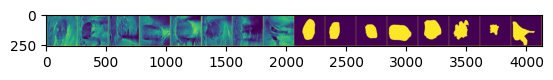

In [8]:

#data_batch, labels_batch = next(iter(train_dataset))
data_batch, mask= next(iter(train_dataset))

print('data_batch.size=',data_batch.size())
mask=mask.unsqueeze(1)
print('mask.size=',mask.size())
#crn=corner_response_map(data_batch)
tmp=torch.cat((data_batch, mask),0)
grid= make_grid(tmp,nrow=1,pad_value=1)
grid=grid.to('cpu')[1,...]
plt.imshow(grid.numpy().transpose((1, 0)))


In [9]:
# ============================================================
# MaxSig-Aware Loss (MSAL)
# ============================================================
class MaxSigFeatureHook:
    """Collects MaxSigLayerNormalized outputs during forward pass."""
    def __init__(self, model):
        self.features = {}
        self.handles = []
        for name, module in model.named_modules():
            if isinstance(module, MaxSigLayerNormalized):
                self.handles.append(
                    module.register_forward_hook(self._make_hook(name))
                )

    def _make_hook(self, name):
        def hook(_, __, output):
            self.features[name] = output
        return hook

    def clear(self):
        self.features.clear()

    def remove(self):
        for h in self.handles:
            h.remove()


def _local_stats(x, k=3):
    """Return (center, mean, median) over kxk patches. x: (B,C,H,W)."""
    B, C, H, W = x.shape
    pad = k // 2
    uf = F.unfold(x, kernel_size=k, padding=pad)              # (B, C*k*k, L)
    uf = uf.view(B, C, k * k, H, W)
    center = uf[:, :, k * k // 2, :, :]
    mean_l = uf.mean(dim=2)
    med_l, _ = uf.median(dim=2)
    return center, mean_l, med_l


class MaxSigAwareLoss(nn.Module):
    """
    L = a_bce * BCE + a_dice * Dice
        + a_sas * SAS
        + a_mbe * MBE
        + a_mmd * MMD
        + a_pdr * PDR(model)
    """
    def __init__(self,
                 alpha_bce=1.0,
                 alpha_dice=1.0,
                 alpha_sas=0.5,
                 alpha_mbe=0.3,
                 alpha_mmd=0.2,
                 alpha_pdr=1e-3,
                 k=3, eps=1e-7):
        super().__init__()
        self.a_bce   = alpha_bce
        self.a_dice  = alpha_dice
        self.a_sas   = alpha_sas
        self.a_mbe   = alpha_mbe
        self.a_mmd   = alpha_mmd
        self.a_pdr   = alpha_pdr
        self.k = k
        self.eps = eps
        self.bce = nn.BCEWithLogitsLoss(reduction='none')

    # ---- term 1: Significance-Aligned Segmentation ----
    def sas_loss(self, probs, targets):
        # significance = |center - mean| + |center - median|  (MaxSig-like)
        pc, pm, pmd = _local_stats(probs, self.k)
        tc, tm, tmd = _local_stats(targets, self.k)
        sig_p = (pc - pm).abs() + (pc - pmd).abs()
        sig_t = (tc - tm).abs() + (tc - tmd).abs()
        # normalize per-sample to [0,1]
        sig_p = sig_p / (sig_p.amax(dim=(2, 3), keepdim=True) + self.eps)
        sig_t = sig_t / (sig_t.amax(dim=(2, 3), keepdim=True) + self.eps)
        return F.l1_loss(sig_p, sig_t)

    # ---- term 2: Max-Bounded Boundary Emphasis ----
    def mbe_loss(self, logits, targets):
        bce = self.bce(logits, targets)                       # (B,1,H,W)
        # boundary proxy: max(abs(center - neighbors)) over kxk
        pc, pm, _ = _local_stats(torch.sigmoid(logits), self.k)
        tc, tm, _ = _local_stats(targets, self.k)
        bnd_p = (pc - pm).abs()
        bnd_t = (tc - tm).abs()
        # max-bounded weight: emphasizes pixels where EITHER pred or GT has local dominance
        w = torch.maximum(bnd_p, bnd_t)
        w = w / (w.mean() + self.eps)
        return (bce * w).mean()

    # ---- term 3: Median-Mean Divergence ----
    def mmd_loss(self, probs, targets):
        _, pm, pmd = _local_stats(probs, self.k)
        _, tm, tmd = _local_stats(targets, self.k)
        div_p = (pm - pmd).abs()
        div_t = (tm - tmd).abs()
        return F.l1_loss(div_p, div_t)

    # ---- term 4: Parameter Diversity Regularization ----
    def pdr_loss(self, model):
        reg = logits = None
        for m in model.modules():
            if isinstance(m, MaxSigLayerNormalized):
                w = torch.sigmoid(m.weight).clamp(self.eps, 1 - self.eps)  # (1,1,K*K,1,1)
                # entropy over the K*K kernel positions -> encourages diversity
                p = w / (w.sum() + self.eps)
                ent = -(p * p.log()).sum()
                # keep weight_center, weight_median positive & balanced
                pos_pen = F.relu(-m.weight_center) + F.relu(-m.weight_median)
                # discourage |wc - wm| being too large (avoid degeneracy)
                bal = (m.weight_center - m.weight_median).abs()
                term = -ent + pos_pen + 0.1 * bal
                reg = term if reg is None else reg + term
        return reg if reg is not None else torch.tensor(0.0, device=next(model.parameters()).device)

    def dice_loss(self, probs, targets):
        inter = (probs * targets).sum(dim=(2, 3))
        union = (probs + targets).sum(dim=(2, 3))
        dice = (2 * inter + self.eps) / (union + self.eps)
        return 1 - dice.mean()

    def forward(self, logits, targets, model=None):
        probs = torch.sigmoid(logits)
        loss  = self.a_bce  * self.bce(logits, targets).mean()
        loss  = loss + self.a_dice * self.dice_loss(probs, targets)
        loss  = loss + self.a_sas  * self.sas_loss(probs, targets)
        loss  = loss + self.a_mbe  * self.mbe_loss(logits, targets)
        loss  = loss + self.a_mmd  * self.mmd_loss(probs, targets)
        if model is not None and self.a_pdr > 0:
            loss = loss + self.a_pdr * self.pdr_loss(model)
        return loss

In [10]:

# ============================================================
# MaxSigLayerNormalized (with proper C_in -> C_out projection)
# ============================================================
class MaxSigLayerNormalized(nn.Module):
    """
    Args:
        ch_in (int): input channels
        ch_out (int): output channels
        kernel_size (int): odd recommended
        stride (int): keep 1 to preserve H,W
        use_sigmoid_input (bool): apply sigmoid(x) before unfolding
    """
    def __init__(
        self,
        ch_in: int,
        ch_out: int,
        kernel_size: int,
        stride: int = 1,
        use_sigmoid_input: bool = True,
    ):
        super().__init__()
        assert kernel_size >= 1
        self.ch_in = ch_in
        self.ch_out = ch_out
        self.kernel_size = kernel_size
        self.stride = stride
        self.use_sigmoid_input = use_sigmoid_input

        self.padding = (kernel_size - 1) // 2
        self.kernel_area = kernel_size ** 2
        self.center_index = self.kernel_area // 2

        # learnable patch weights / bias (shared)
        self.weight = nn.Parameter(torch.rand(1, 1, self.kernel_area, 1, 1))
        self.bias   = nn.Parameter(torch.zeros(1, 1, self.kernel_area, 1, 1))

        # learnable scalars
        self.weight_center = nn.Parameter(torch.tensor(1.0))
        self.weight_median = nn.Parameter(torch.tensor(1.0))

        # proper projection
        self.proj = nn.Conv2d(ch_in, ch_out, kernel_size=1, bias=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, C_in, H, W = x.shape
        assert C_in == self.ch_in, f"Expected {self.ch_in} channels, got {C_in}"

        x_in = torch.sigmoid(x) if self.use_sigmoid_input else x

        x_unfold = F.unfold(
            x_in,
            kernel_size=self.kernel_size,
            padding=self.padding,
            stride=self.stride,
        )  # (B, C_in*K*K, L)

        _, CK2, L = x_unfold.shape
        assert CK2 == C_in * self.kernel_area

        out_h = (H + 2 * self.padding - self.kernel_size) // self.stride + 1
        out_w = (W + 2 * self.padding - self.kernel_size) // self.stride + 1

        x_unfold = x_unfold.view(B, C_in, self.kernel_area, out_h, out_w)

        w = torch.sigmoid(self.weight)  # (1,1,K*K,1,1)
        b = torch.sigmoid(self.bias)    # (1,1,K*K,1,1)

        D = torch.maximum(w, x_unfold) + b  # (B,C,K*K,out_h,out_w)

        mean_stat = torch.mean(D, dim=2)         # (B,C,out_h,out_w)
        median_stat, _ = torch.median(D, dim=2)  # (B,C,out_h,out_w)

        center_values = x_unfold[:, :, self.center_index, :, :]  # (B,C,out_h,out_w)

        out = (
            self.weight_center * center_values
            + self.weight_median * median_stat
            - mean_stat
        )  # (B,C_in,out_h,out_w)

        out = self.proj(out)  # (B,C_out,out_h,out_w)
        return out


# ============================================================
# Encoder integration helpers
# ============================================================
class DoubleConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, 1, 1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, 3, 1, 1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.conv(x)


class DownBlockWithMaxSig(nn.Module):
    """
    Down block: DoubleConv -> (optional MaxSigLayerNormalized in main stream)
    """
    def __init__(
        self,
        in_ch: int,
        out_ch: int,
        use_maxsig: bool,
        kernel_sig: int = 3,
        maxsig_mode: str = "gated",   # "gated" (recommended) or "direct"
        gamma_init: float = 0.0,      # gate starts at 0 => baseline at init
        use_sigmoid_input: bool = True,
    ):
        super().__init__()
        assert maxsig_mode in ("gated", "direct")
        self.use_maxsig = use_maxsig
        self.maxsig_mode = maxsig_mode

        self.conv = DoubleConv(in_ch, out_ch)

        if use_maxsig:
            self.maxsig = MaxSigLayerNormalized(
                ch_in=out_ch,
                ch_out=out_ch,
                kernel_size=kernel_sig,
                stride=1,
                use_sigmoid_input=use_sigmoid_input,
            )
            # light post-processing helps stabilize
            self.post = nn.Sequential(
                nn.BatchNorm2d(out_ch),
                nn.LeakyReLU(0.1, inplace=True),
            )
            if maxsig_mode == "gated":
                self.gamma = nn.Parameter(torch.tensor(gamma_init))
        else:
            self.maxsig = None
            self.post = None

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.conv(x)

        if not self.use_maxsig:
            return x

        m = self.maxsig(x)
        m = self.post(m)

        if self.maxsig_mode == "direct":
            # direct replacement/transform (riskier)
            return m

        # gated residual injection (recommended)
        return x + self.gamma * m


# ============================================================
# UNet (MaxSig applied in DOWN path, not just skips)
# ============================================================
class UNet(nn.Module):
    """
    U-Net with MaxSigLayerNormalized applied inside encoder stages:
      x = DownBlockWithMaxSig(x)
      skip.append(x)
      x = pool(x)

    Params:
      maxsig_down_stages: indices of encoder stages where MaxSig is applied.
        features=[64,128,256,512]
        stage 0 => 64, stage 1 => 128, etc.
    """
    def __init__(
        self,
        in_channels: int = 1,
        out_channels: int = 1,          # binary segmentation: 1; multiclass: num_classes
        features=(64, 128, 256, 512),
        maxsig_down_stages=(1, 2),      # recommended start: (2,) or (1,2)
        maxsig_kernel: int = 3,
        maxsig_mode: str = "gated",     # "gated" or "direct"
        gamma_init: float = 0.0,
        use_sigmoid_input: bool = True,
    ):
        super().__init__()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.downs = nn.ModuleList()
        self.ups = nn.ModuleList()

        maxsig_down_stages = set(maxsig_down_stages)
        ch = in_channels
        feats = list(features)

        # Encoder
        for i, feat in enumerate(feats):
            use_maxsig = i in maxsig_down_stages
            self.downs.append(
                DownBlockWithMaxSig(
                    in_ch=ch,
                    out_ch=feat,
                    use_maxsig=use_maxsig,
                    kernel_sig=maxsig_kernel,
                    maxsig_mode=maxsig_mode,
                    gamma_init=gamma_init,
                    use_sigmoid_input=use_sigmoid_input,
                )
            )
            ch = feat

        # Bottleneck
        self.bottleneck = DoubleConv(feats[-1], feats[-1] * 2)

        # Decoder
        for feat in reversed(feats):
            self.ups.append(nn.ConvTranspose2d(feat * 2, feat, kernel_size=2, stride=2))
            self.ups.append(DoubleConv(feat * 2, feat))

        self.final_conv = nn.Conv2d(feats[0], out_channels, kernel_size=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        skip_connections = []

        for down in self.downs:
            x = down(x)                 # <-- MaxSig is INSIDE down path here
            skip_connections.append(x)
            x = self.pool(x)

        x = self.bottleneck(x)

        skip_connections = skip_connections[::-1]

        for idx in range(0, len(self.ups), 2):
            x = self.ups[idx](x)
            skip = skip_connections[idx // 2]

            if x.shape[2:] != skip.shape[2:]:
                x = TF.resize(x, size=skip.shape[2:])

            x = torch.cat((skip, x), dim=1)
            x = self.ups[idx + 1](x)

        return self.final_conv(x)


# ============================================================
torch.manual_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"

# ---- Binary semantic segmentation example ----
model = UNet(
    in_channels=1,
    out_channels=1,                 # binary
    features=(64, 128, 256, 512),
    maxsig_down_stages=(1, 2),      # start with (2,) if you want safer
    maxsig_kernel=3,
    maxsig_mode="gated",            # recommended gated or direct
    gamma_init=0.0,                 # starts as baseline UNet
    use_sigmoid_input=True,
).to(device)


In [11]:

data_batch,mask_name = next(iter(train_dataset))
print("data_batch.size=",data_batch.size())

#criterion = nn.BCEWithLogitsLoss()
criterion = MaxSigAwareLoss(
    alpha_bce=1.0, alpha_dice=1.0,
    alpha_sas=0.5, alpha_mbe=0.3, alpha_mmd=0.2, alpha_pdr=1e-3,
).to(device)
optimizer = optim.AdamW(model.parameters(),lr=1e-4)

scheduler = StepLR(optimizer, step_size=100, gamma=0.83)
scaler = torch.amp.GradScaler('cuda')

best_valid_dice=0
best_epoch=0
train_loss_plot=[]
val_loss_plot=[]
val_dice_plot=[]
last_lr=scheduler.get_last_lr()

for epoch in range(config['epochs']):

    if(last_lr != scheduler.get_last_lr()):
        print(80*'-')
        #net.load_state_dict(torch.load('f:/pred_img/best-model.pt'))
        print(f'The lr changed from {last_lr} to {scheduler.get_last_lr()}. thus previous best model loaded!')
        last_lr = scheduler.get_last_lr()

    print("\r\nepoch ",epoch+1," started!",' LR=', last_lr)

    t_start = perf_counter()

    #model training step
    running_loss = 0.0
    model.train()
    for inputs,mask in train_dataset:

        optimizer.zero_grad()
        with torch.autocast(device_type="cuda"):
            outputs = model(inputs.to(device))
            labels=mask.to(device).unsqueeze(1)
            loss = criterion(outputs, labels)

        running_loss += loss.item()
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

    ep_loss=running_loss / len(train_dataset)
    print("train_loss: " ,ep_loss)
    train_loss_plot.append(ep_loss)
    scheduler.step()

    #model evaluation step
    dice_score = 0
    val_loss = 0.0
    with torch.no_grad():
        model.eval()
        for inputs,mask in val_dataset:

            inputs=inputs.to(device)
            preds =model(inputs)
            labels=mask.to(device).unsqueeze(1)
            loss = criterion(preds, labels)
            val_loss += loss.item()

            pred_sig=torch.sigmoid(preds)

            preds=(pred_sig>0.5).float()
            intersection=(preds * labels).sum()
            union=(preds + labels).sum()
            dice_score += (2 * intersection / union)

    ep_loss=val_loss / len(val_dataset)
    print("val_loss: " ,ep_loss)
    val_loss_plot.append(ep_loss)
    epoch_dc= float(dice_score/len(val_dataset))
    val_dice_plot.append(epoch_dc)
    print(f"Validation_Dice Score = {epoch_dc:.12f}")
    if(best_valid_dice< epoch_dc):
        best_valid_dice=epoch_dc
        best_epoch=epoch
        torch.save(model.state_dict(), ROOT+'best-model-msaloss.pt')
        print('The best model saved...')
        #tmp=torch.cat((labels,preds),0)
        #grid= make_grid(tmp,nrow=6,pad_value=1)
        #torchvision.utils.save_image(grid, f"f:/pred_img/sim/all/{epoch+1}.tif")

    print('Best validation dice=',best_valid_dice, ' in epoch ', best_epoch+1)
    #print(net.m1.weight.detach().cpu().numpy())
    print(f"Epoch finished in {perf_counter()-t_start} seconds.\r\n")


data_batch.size= torch.Size([8, 1, 256, 256])

epoch  1  started!  LR= [0.0001]
train_loss:  1.5558378526142664
val_loss:  1.5339194297790528
Validation_Dice Score = 0.256418764591
The best model saved...
Best validation dice= 0.25641876459121704  in epoch  1
Epoch finished in 13.24131288001081 seconds.


epoch  2  started!  LR= [0.0001]
train_loss:  1.2932932660693215
val_loss:  1.1624221324920654
Validation_Dice Score = 0.742344856262
The best model saved...
Best validation dice= 0.742344856262207  in epoch  2
Epoch finished in 6.146068238973385 seconds.


epoch  3  started!  LR= [0.0001]
train_loss:  1.1214975260552906
val_loss:  1.1090452194213867
Validation_Dice Score = 0.690750718117
Best validation dice= 0.742344856262207  in epoch  2
Epoch finished in 5.234128957003122 seconds.


epoch  4  started!  LR= [0.0001]
train_loss:  1.0543139718827748
val_loss:  0.9602865815162659
Validation_Dice Score = 0.779831171036
The best model saved...
Best validation dice= 0.7798311710357666  i

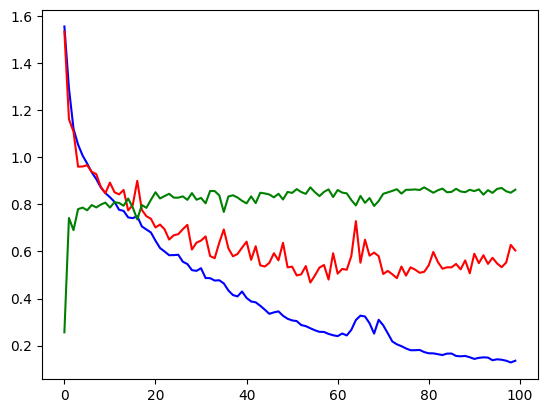

In [12]:
plt.plot(train_loss_plot, color='blue',label='train_loss')
plt.plot(val_loss_plot, color='red',label='val_loss')
plt.plot(val_dice_plot ,color='green',label='val_dice')
plt.show()

In [13]:
#test dataset

images_dir= ROOT + 'dataset/test/images/'
masks_dir= ROOT + 'dataset/test/masks/'
batch_size=config['batch_size']
shuffle=True

test_transform = A.Compose([

    #A.PadIfNeeded (min_height=790, min_width=790, border_mode=cv2.BORDER_CONSTANT, value=0,always_apply=True,  p=1.0),
    A.Resize(256,256),
    ToTensorV2()])

test_ds=mydataset(images_dir=images_dir,masks_dir=masks_dir,transforms_img=test_transform)
print("number of loaded test images: ",test_ds.__len__())

test_dataset = DataLoader(test_ds,batch_size=batch_size,shuffle=shuffle)
print("loaded", len(test_dataset), "test batches.")

number of loaded test images:  35
loaded 5 test batches.


In [17]:
torch.manual_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"

# ---- Binary semantic segmentation example ----
model = UNet(
    in_channels=1,
    out_channels=1,                 # binary
    features=(64, 128, 256, 512),
    maxsig_down_stages=(1, 2),      # start with (2,) if you want safer
    maxsig_kernel=3,
    maxsig_mode="gated",            # recommended gated or direct
    gamma_init=0.0,                 # starts as baseline UNet
    use_sigmoid_input=True,
).to(device)
#model evaluation step
dice_score = 0
model.load_state_dict(torch.load('best-model-msaloss.pt'))
with torch.no_grad():
    model.eval()
    for inputs,mask in test_dataset:

        inputs=inputs.to(device)
        preds =model(inputs)
        labels=mask.to(device).unsqueeze(1)        
        pred_sig=torch.sigmoid(preds)
        preds=(pred_sig>0.5).float()
        intersection=(preds * labels).sum()
        union=(preds + labels).sum()
        dice_score += (2 * intersection / union)

epoch_dc= float(dice_score/len(test_dataset))

print(f"test Dice Score = {epoch_dc:.12f}")


test Dice Score = 0.857921123505
